# Combined Figure: Input Blanking & Missing Values

This notebook combines the plots from `nb_input_blanking.ipynb` and `nb_missing_values.ipynb` into a single figure with two subplots using GridSpec.

Evaluation results are cached in `./output/` to avoid re-running expensive model predictions. Delete the cached files to force re-evaluation.

In [6]:
from os.path import dirname, abspath, join
from os import makedirs
import sys
import numpy as np
import pandas as pd
import re
import json
from omegaconf import OmegaConf
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

root_path = dirname(abspath("./"))
sys.path.append(root_path)
from proT.evaluation.predict import *
from proT.evaluation.metrics import *
from proT.evaluation.eval_sweeps import eval_sweeps

# plotting standard settings
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['lines.linewidth'] = 1.5
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('colorblind'))
plt.rcParams['lines.linewidth'] = 2.0

output_dir = "./output"
makedirs(output_dir, exist_ok=True)

## Lib

In [7]:
def build_models_sweep_from_baseline_df(df):
    """
    Build models_sweep list from baseline results dataframe.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Dataframe with columns: 'model', 'dataset', 'best_trial'
        where 'best_trial' points to the kfold_summary.json file
    
    Returns:
    --------
    list of dict
        List of dictionaries with keys: 'model', 'config_path', 'checkpoint_path'
    """
    models_sweep = []
    
    for idx, row in df.iterrows():
        model_name = row['model']
        best_trial_path = row['best_trial']
        
        model_id = f"{model_name}"
        
        best_trial_path = best_trial_path.replace('\\', '/')
        parts = best_trial_path.split('/')
        
        try:
            optuna_idx = parts.index('optuna')
            base_folder_parts = parts[:optuna_idx]
            base_folder = '/'.join(base_folder_parts)
            run_folder = parts[optuna_idx + 1]
        except (ValueError, IndexError) as e:
            print(f"Warning: Could not parse path for {model_id}: {best_trial_path}")
            print(f"Error: {e}")
            continue
        
        config_pattern = os.path.join(base_folder, "config_*.yaml")
        config_files = glob.glob(config_pattern)
        
        if not config_files:
            print(f"Warning: No config file found for {model_id} at {config_pattern}")
            continue
        
        config_path = config_files[0]
        
        try:
            kfold_summary = OmegaConf.load(best_trial_path)
            best_fold_number = kfold_summary.best_fold.fold_number
        except Exception as e:
            print(f"Warning: Could not load kfold_summary for {model_id}: {e}")
            continue
        
        checkpoint_path = os.path.join(
            base_folder,
            'optuna',
            run_folder,
            f'k_{best_fold_number}',
            'checkpoints',
            'best_checkpoint.ckpt'
        )
        
        if not os.path.exists(checkpoint_path):
            print(f"Warning: Checkpoint not found for {model_id}: {checkpoint_path}")
            checkpoint_path = checkpoint_path.replace('\\', '/')
            if not os.path.exists(checkpoint_path):
                continue
        
        models_sweep.append({
            "model": model_id,
            "config_path": config_path,
            "checkpoint_path": checkpoint_path
        })
        
        print(f"Added {model_id}:")
        print(f"  Config: {config_path}")
        print(f"  Checkpoint: {checkpoint_path}")
    
    return models_sweep

## Data: Input Blanking

Cached to `./output/blanking_metrics.parquet`. Delete the file to re-run evaluation.

In [8]:
blanking_cache_path = join(output_dir, "blanking_metrics.parquet")

if os.path.exists(blanking_cache_path):
    print(f"Loading cached blanking results from {blanking_cache_path}")
    df_blanking = pd.read_parquet(blanking_cache_path)
else:
    print("No cached blanking results found. Running evaluation...")
    
    df_baseline = pd.read_csv("./output/baseline_results.csv")
    df_baseline = df_baseline.set_index(["dataset", "fusion", "model"]).loc["ishigami"].loc["sum"].loc[["GRU", "proT", "proTNoNAIM"]].reset_index()
    
    models_sweep = build_models_sweep_from_baseline_df(df_baseline)
    datadir_path = "../data/input"
    
    blank_vector = [0, 0.2, 0.4, 0.6, 0.8]
    
    df_blanking = None
    
    for model_dict in models_sweep:
        model           = model_dict["model"]
        config_path     = model_dict["config_path"]
        checkpoint_path = model_dict["checkpoint_path"]
    
        config = OmegaConf.load(config_path)
        df_blank = None
    
        for blank_val in blank_vector:
            if blank_val == 0:
                blanking_fn = None
            else:
                blanking_fn = create_input_blanking_fn(
                    beta=blank_val,
                    val_idx=config["data"]["val_idx"],
                    seed=42
                )
    
            results = predict_test_from_ckpt(config, datadir_path, checkpoint_path, input_conditioning_fn=blanking_fn)
            metrics_df = compute_prediction_metrics(results, target_feature_idx=config["data"]["val_idx"])
            metrics_df["Blanking"] = blank_val
    
            if df_blank is None:
                df_blank = metrics_df
            else:
                df_blank = pd.concat([df_blank, metrics_df], ignore_index=True)
        
        df_blank["Model"] = model
        if df_blanking is None:
            df_blanking = df_blank
        else:
            df_blanking = pd.concat([df_blanking, df_blank], ignore_index=True)
    
    df_blanking["Model"] = df_blanking["Model"].map({
        "GRU": "GRU",
        "proT": "proT",
        "proTNoNAIM": "proT (no NAIM)"
    })
    
    # Cache results
    df_blanking.to_parquet(blanking_cache_path, index=False)
    print(f"Saved blanking results to {blanking_cache_path}")

df_blanking.head()

Loading cached blanking results from ./output\blanking_metrics.parquet


,index,R2,MSE,MAE,RMSE,Blanking,Model
0,0,-0.121763,0.000063,0.006840,0.007931,0.0,GRU
1,1,-0.057305,0.001011,0.025426,0.031801,0.0,GRU
2,2,0.097329,0.000032,0.004821,0.005674,0.0,GRU
3,3,-0.420824,0.000023,0.004125,0.004807,0.0,GRU
4,4,0.003472,0.138480,0.305156,0.372129,0.0,GRU


## Data: Missing Values

Cached to `./output/missing_metrics.parquet`. Delete the file to re-run evaluation.

In [9]:
missing_cache_path = join(output_dir, "missing_metrics.parquet")

if os.path.exists(missing_cache_path):
    print(f"Loading cached missing values results from {missing_cache_path}")
    df_missing = pd.read_parquet(missing_cache_path)
else:
    print("No cached missing values results found. Running evaluation...")
    
    datadir_path = "../data/input"
    experiment_dir = "../experiments/miss_vals/euler/"
    df_missing = eval_sweeps(
        filepath=experiment_dir,
        datadir_path=datadir_path
    )
    
    df_missing["p_blank"] = df_missing['model_folder'].apply(
        lambda x: re.search(r'_([\d]+[.]?[\d]*)$', x).group(1) if re.search(r'_([\d]+[.]?[\d]*)$', x) else None
    )
    
    options = ["_GRU_", "_proT_", "_proTNoNAIM_"]
    df_missing['model'] = df_missing['level_0'].apply(
        lambda x: next((opt for opt in options if opt in x), None)
    )
    df_missing["model"] = df_missing["model"].map({
        "_GRU_": "GRU",
        "_proT_": "proT",
        "_proTNoNAIM_": "proT (no NAIM)",
    })
    
    # Cache results
    df_missing.to_parquet(missing_cache_path, index=False)
    print(f"Saved missing values results to {missing_cache_path}")

df_missing.head()

Loading cached missing values results from ./output\missing_metrics.parquet


,index,R2,MSE,MAE,RMSE,model_folder,level_4,level_3,level_2,level_1,level_0,p_blank,model
0,0,0.380500,0.000035,0.005150,0.005894,combo_input_p_blank_0,combo_input_p_blank_0,combinations,runs,sweeper,miss_vals_GRU_ishigami_sum_52210751,0,GRU
1,1,-0.258834,0.001204,0.027261,0.034700,combo_input_p_blank_0,combo_input_p_blank_0,combinations,runs,sweeper,miss_vals_GRU_ishigami_sum_52210751,0,GRU
2,2,0.715008,0.000010,0.002634,0.003188,combo_input_p_blank_0,combo_input_p_blank_0,combinations,runs,sweeper,miss_vals_GRU_ishigami_sum_52210751,0,GRU
3,3,-0.178799,0.000019,0.003383,0.004378,combo_input_p_blank_0,combo_input_p_blank_0,combinations,runs,sweeper,miss_vals_GRU_ishigami_sum_52210751,0,GRU
4,4,0.019131,0.136304,0.304819,0.369194,combo_input_p_blank_0,combo_input_p_blank_0,combinations,runs,sweeper,miss_vals_GRU_ishigami_sum_52210751,0,GRU


## Combined Figure

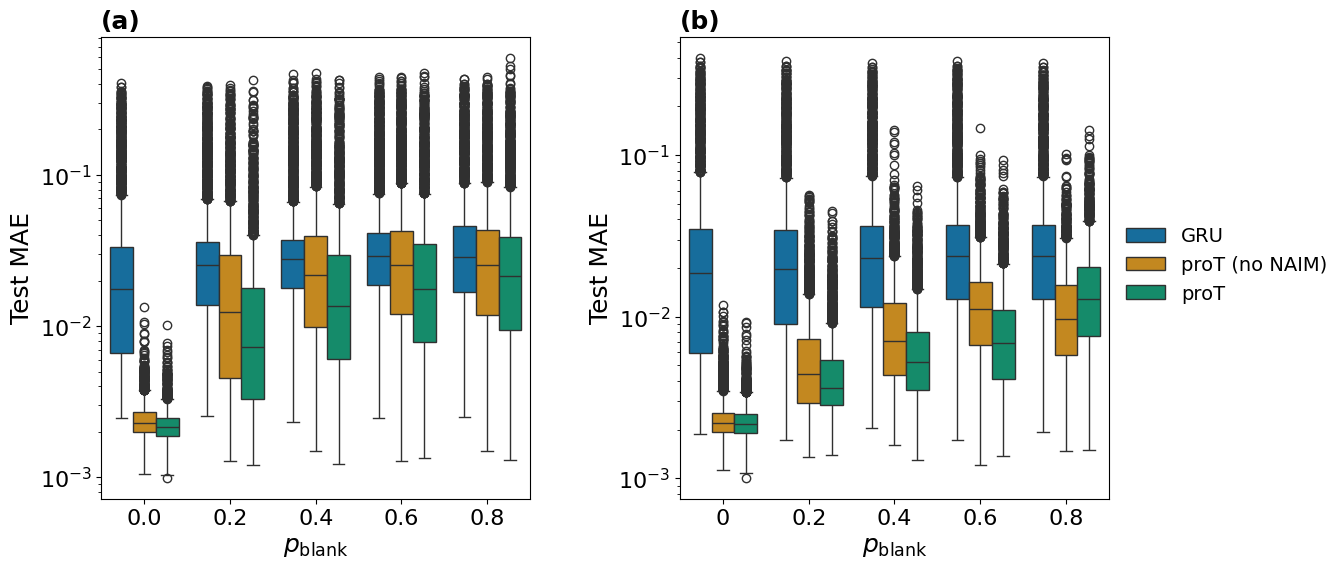

In [18]:
save_dir = "./figures"
makedirs(save_dir, exist_ok=True)

# --- Create combined figure with GridSpec ---
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Left panel: Input Blanking ---
ax1 = fig.add_subplot(gs[0])
sns.boxplot(
    data=df_blanking,
    x="Blanking",
    y="MAE",
    hue="Model",
    hue_order=["GRU", "proT (no NAIM)", "proT"],
    ax=ax1,
    palette="colorblind",
)
ax1.set_xlabel(r"$p_\text{blank}$")
ax1.set_ylabel("Test MAE")
ax1.set_yscale("log")
ax1.get_legend().remove()
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: Missing Values ---
ax2 = fig.add_subplot(gs[1])
sns.boxplot(
    data=df_missing,
    x="p_blank",
    y="MAE",
    hue="model",
    hue_order=["GRU", "proT (no NAIM)", "proT"],
    ax=ax2,
    palette="colorblind"
)
ax2.set_xlabel(r"$p_\text{blank}$")
ax2.set_ylabel("Test MAE")
ax2.set_yscale("log")
ax2.get_legend().remove()
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Shared legend ---
handles, labels = ax1.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(0.9, 0.5),
    frameon=False,
    ncol=1
)

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_blanking_and_missing.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()